# Commissioning SLA Analysis

**Goal:** Measure how often equipment went from Green Tag (passed initial inspection) to Blue Tag (fully commissioned) within the 5 business day SLA, and find when the team fell furthest behind.

**Tools:** Python (pandas), Matplotlib, Plotly

**Data:** Commissioning tag log from a real project, masked with `mask_data.py` so each unit has a random ID and only the discipline and tag dates are kept. The data file itself stays private.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

SLA_DAYS = 5
DATA_PATH = 'data/tag_log_masked.csv'   # masked export, kept private

df = pd.read_csv(DATA_PATH, parse_dates=['Green Tag', 'Blue Tag', 'Tag Date'])
print(f"Tag records: {len(df):,}")
print(f"Columns: {df.columns.tolist()}")
print(df['Tag Type'].value_counts())

Tag records: 21,383
Columns: ['Unit ID', 'Discipline', 'Tag Type', 'Green Tag', 'Blue Tag', 'Tag Date']
Tag Type
Blue     10694
Green    10689
Name: count, dtype: int64


## Step 1: Roll up to one row per equipment ID

Each unit has a Green Tag row and a Blue Tag row in the log. I keep the latest date of each type in case a unit was re-tagged.

In [2]:
green = (df[df['Tag Type'] == 'Green']
         .groupby('Unit ID')['Green Tag'].max()
         .rename('Green Tag Date'))
blue = (df[df['Tag Type'] == 'Blue']
        .groupby('Unit ID')['Blue Tag'].max()
        .rename('Blue Tag Date'))

discipline = df.groupby('Unit ID')['Discipline'].first()

sla = pd.concat([green, blue, discipline], axis=1).reset_index()
print(f"Equipment units: {len(sla):,}")

Equipment units: 10,693


## Step 2: Deadline and SLA status

- **Deadline:** Green Tag date plus 5 business days
- **As of date:** the last date in the export, so results don't change when the notebook is rerun
- **Data Issue:** Blue Tag dated before the Green Tag. These can't be scored, so they are flagged and excluded

In [3]:
sla['Deadline'] = sla['Green Tag Date'] + pd.offsets.BDay(SLA_DAYS)
as_of = df[['Green Tag', 'Blue Tag', 'Tag Date']].max().max()
print(f"As of: {as_of.date()}")

def sla_status(row):
    g, b, dl = row['Green Tag Date'], row['Blue Tag Date'], row['Deadline']
    if pd.isna(g):
        return 'N/A'
    if pd.notna(b) and b < g:
        return 'Data Issue'
    if pd.isna(b):
        return 'Past Due' if as_of > dl else 'In Window'
    return 'On Time' if b <= dl else 'Late'

sla['SLA Status'] = sla.apply(sla_status, axis=1)
sla['Turnaround Days'] = (sla['Blue Tag Date'] - sla['Green Tag Date']).dt.days

print(sla['SLA Status'].value_counts())

As of: 2025-12-02
SLA Status
On Time     6329
Late        4218
Past Due     137
N/A            9
Name: count, dtype: int64


## Step 3: Overall SLA performance

In [4]:
scored = sla[sla['SLA Status'].isin(['On Time', 'Late', 'Past Due', 'In Window'])]
summary = (scored['SLA Status'].value_counts()
           .to_frame('Count')
           .assign(Percent=lambda t: (t['Count'] / t['Count'].sum() * 100).round(1)))
print(f"Scored units: {len(scored):,}")
summary

Scored units: 10,684


,Count,Percent
SLA Status,,
On Time,6329,59.2
Late,4218,39.5
Past Due,137,1.3


In [5]:
done = scored.dropna(subset=['Turnaround Days'])
print(f"Median turnaround: {done['Turnaround Days'].median():.0f} days")
print(f"75th percentile:   {done['Turnaround Days'].quantile(.75):.0f} days")
print(f"Longest:           {done['Turnaround Days'].max():.0f} days")

Median turnaround: 5 days
75th percentile:   20 days
Longest:           598 days


## Step 4: Late items by month

Grouped by the month the deadline fell in. This shows when the team was furthest behind.

Peak month: August 2024 with 467 late items


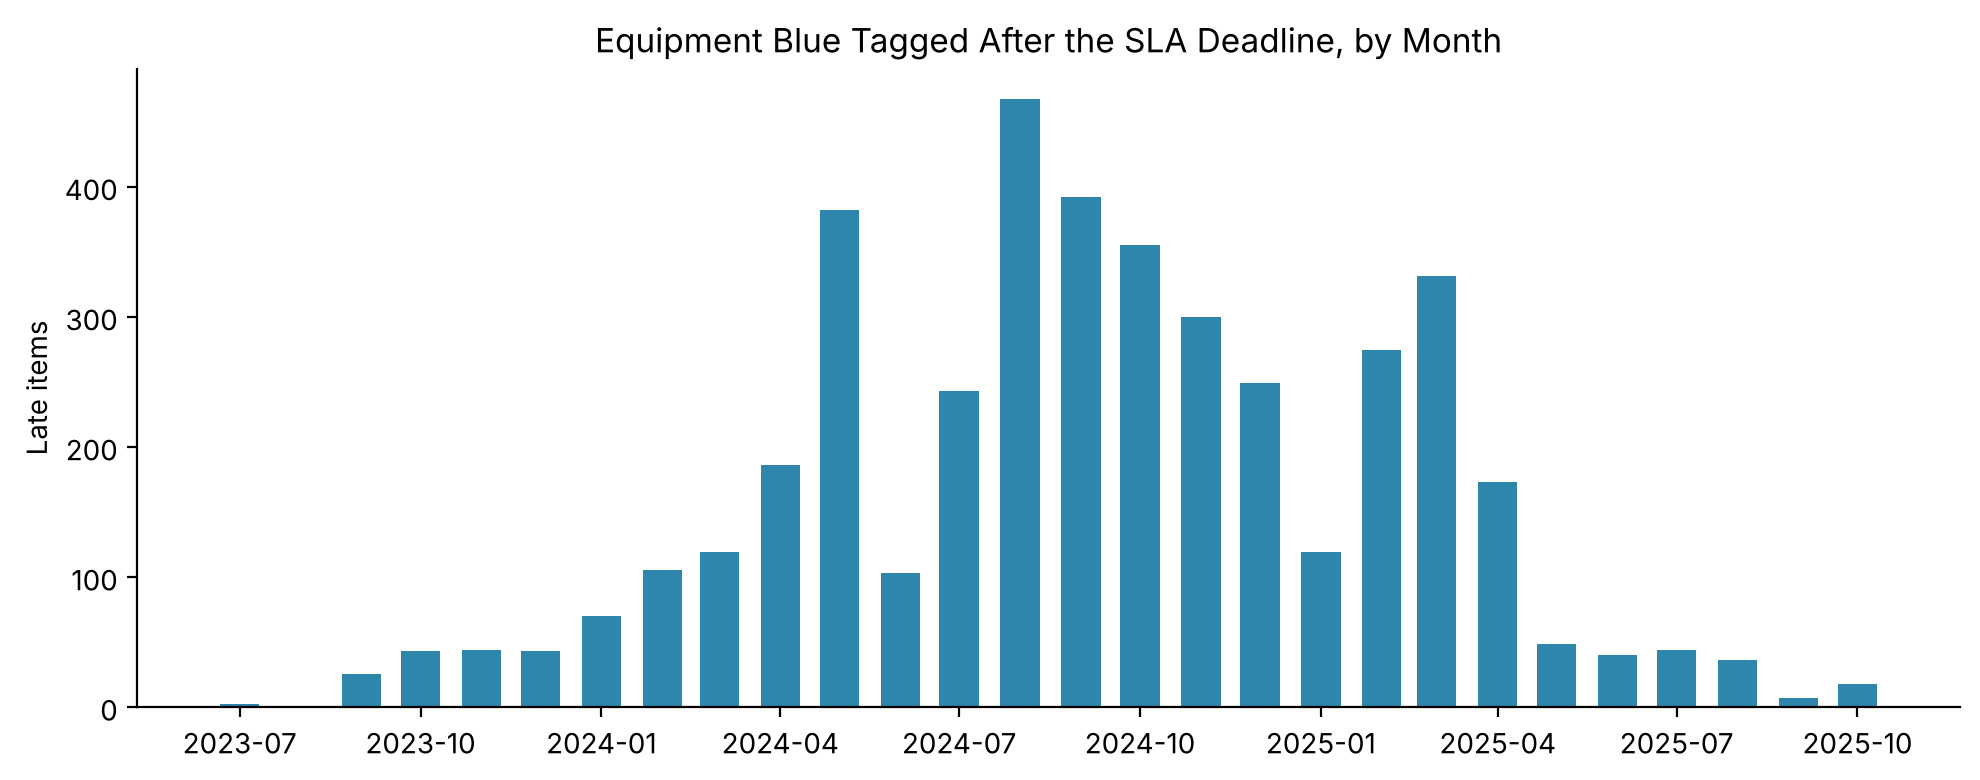

In [6]:
late = scored[scored['SLA Status'] == 'Late'].copy()
late['Month'] = late['Deadline'].dt.to_period('M').dt.to_timestamp()
late_monthly = late.groupby('Month').size().rename('Late Items').reset_index()

peak = late_monthly.loc[late_monthly['Late Items'].idxmax()]
print(f"Peak month: {peak['Month']:%B %Y} with {peak['Late Items']} late items")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(late_monthly['Month'], late_monthly['Late Items'], width=20, color='#2E86AB')
ax.set_title('Equipment Blue Tagged After the SLA Deadline, by Month')
ax.set_ylabel('Late items')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('images/late_by_month.png', dpi=150)
plt.show()

## Step 5: SLA performance by discipline

Breaking results out by trade shows where the delays really came from.

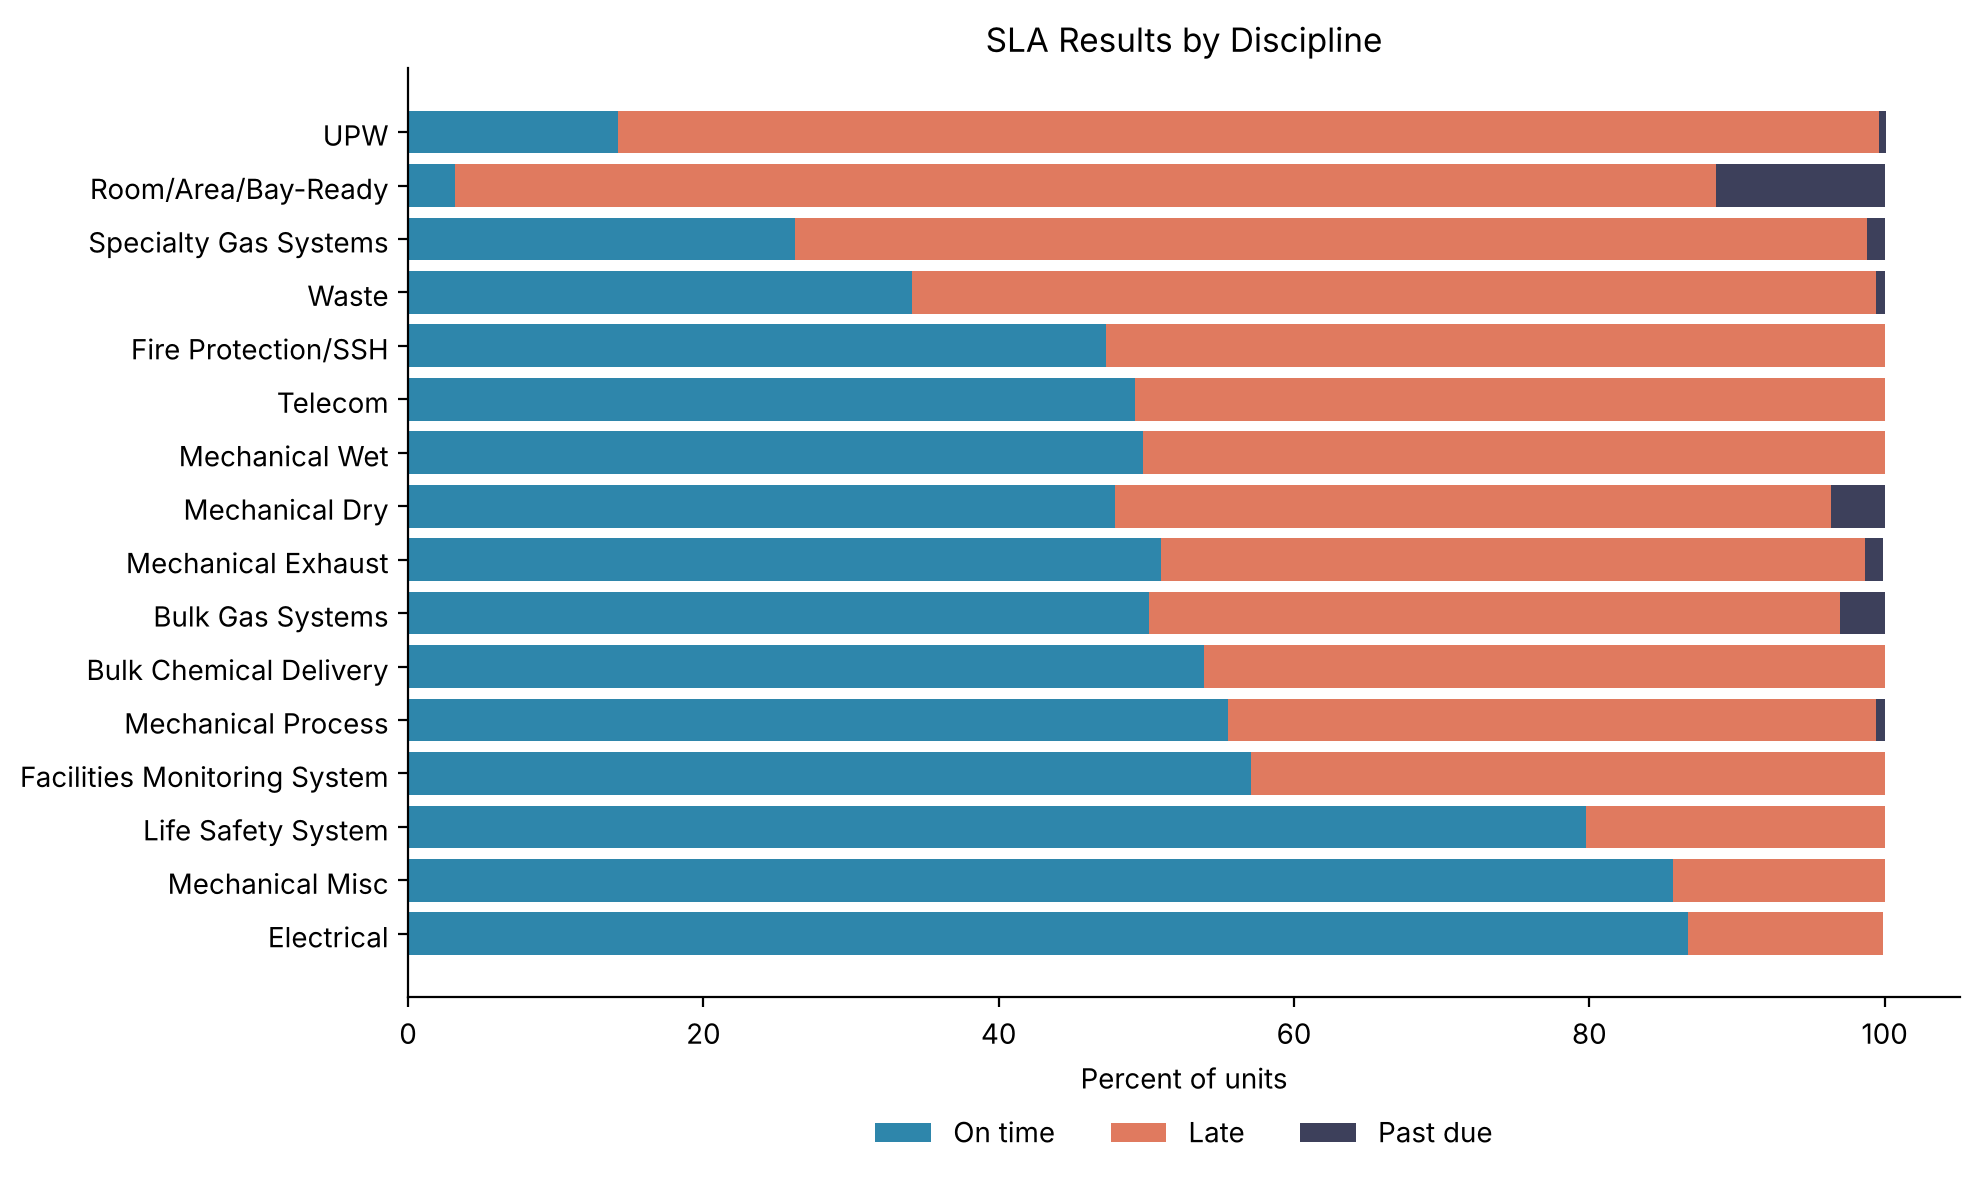

SLA Status,Units,On Time,Late,Past Due
Discipline,,,,
UPW,862,14.2,85.4,0.5
Room/Area/Bay-Ready,664,3.2,85.4,11.4
Specialty Gas Systems,164,26.2,72.6,1.2
Waste,663,34.1,65.3,0.6
Fire Protection/SSH,300,47.3,52.7,0.0
Telecom,61,49.2,50.8,0.0
Mechanical Wet,321,49.8,50.2,0.0
Mechanical Dry,726,47.9,48.5,3.6
Mechanical Exhaust,484,51.0,47.7,1.2


In [7]:
by_disc = (scored.groupby('Discipline')['SLA Status']
           .value_counts(normalize=True).unstack(fill_value=0) * 100).round(1)
by_disc['Units'] = scored.groupby('Discipline').size()
by_disc = by_disc[['Units', 'On Time', 'Late', 'Past Due']].sort_values('Late')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(by_disc.index, by_disc['On Time'], color='#2E86AB', label='On time')
ax.barh(by_disc.index, by_disc['Late'], left=by_disc['On Time'], color='#E07A5F', label='Late')
ax.barh(by_disc.index, by_disc['Past Due'], left=by_disc['On Time'] + by_disc['Late'],
        color='#3D405B', label='Past due')
ax.set_xlabel('Percent of units')
ax.set_title('SLA Results by Discipline')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('images/sla_by_discipline.png', dpi=150)
plt.show()

by_disc.sort_values('Late', ascending=False)

## Step 6: Items still past due

In [8]:
past_due = scored[scored['SLA Status'] == 'Past Due'].copy()
past_due['Month'] = past_due['Deadline'].dt.to_period('M').dt.to_timestamp()
pd_monthly = past_due.groupby('Month').size().rename('Past Due Items').reset_index()
print(f"Still past due as of {as_of.date()}: {len(past_due)}")
pd_monthly

Still past due as of 2025-12-02: 137


,Month,Past Due Items
0,2024-03-01,1
1,2024-08-01,2
2,2024-09-01,1
3,2024-11-01,4
4,2024-12-01,3
5,2025-01-01,6
6,2025-02-01,18
7,2025-03-01,38
8,2025-04-01,28
9,2025-05-01,11


## Step 7: Check against the original Excel tracker

I first built this tracker in Excel with formulas and a pivot table. Rebuilding it in Python was a chance to check that work. The counts below come from the Excel pivot.

In [9]:
excel = pd.Series({'On Time': 6332, 'Late': 4218, 'Past Due': 137}, name='Excel')
python = scored['SLA Status'].value_counts().rename('Python')
check = pd.concat([excel, python], axis=1)
check['Difference'] = check['Python'] - check['Excel']
check

,Excel,Python,Difference
On Time,6332,6329,-3
Late,4218,4218,0
Past Due,137,137,0


In [10]:
# The 3 extra "On Time" units in Excel: Blue Tag with no Green Tag
no_green = sla[sla['Green Tag Date'].isna() & sla['Blue Tag Date'].notna()]
print(f"Units with a Blue Tag but no Green Tag: {len(no_green)}")

Units with a Blue Tag but no Green Tag: 3


The two versions match on 10,684 units. The 3 that differ have a Blue Tag but no Green Tag. The Excel formula only checked the Blue Tag date, so it scored them On Time. With no Green Tag there is no deadline, so Python marks them N/A. Rebuilding the logic in code caught a bug in the original sheet.

## Step 8: Export results

In [11]:
late_monthly.to_csv('output/late_by_month.csv', index=False)
pd_monthly.to_csv('output/past_due_by_month.csv', index=False)
summary.to_csv('output/sla_summary.csv')
by_disc.to_csv('output/sla_by_discipline.csv')

chart = px.bar(late_monthly, x='Month', y='Late Items',
               title='Late Equipment by Month (interactive)')
chart.write_html('output/late_by_month.html', include_plotlyjs='cdn')
print('Saved CSVs and interactive chart to output/')

Saved CSVs and interactive chart to output/


## Takeaways

- 59% of units met the 5 business day SLA and 40% were late. Only about 1% were still open at the end
- The median turnaround was 5 days, right at the SLA line, so small slips pushed a lot of units over
- Discipline mattered more than anything else. Electrical, the biggest group, was 87% on time, while UPW and Room/Area/Bay-Ready were both about 85% late
- Late items peaked in August 2024 (467 units). After a second rise in early 2025 they dropped off
- Past due items piled up most in March 2025, so that was when follow-up was needed most
- Rebuilding the Excel tracker in Python matched on 10,684 units and caught 3 that the original formula scored wrong

## Limitations

- Business days skip weekends but not holidays.
- The masked file keeps discipline and dates only, so the analysis can't go below the discipline level.